# 02 — Phân tích dữ liệu khám phá (EDA): IBM Telco Customer Churn

**Đề tài 18 — Mức 1 (Thực tập ngành).** Notebook này phục vụ Chương 4 của báo cáo (mục 4.2 và 4.3).

**Nguyên tắc của notebook**
- Chỉ đọc **file CSV gốc** `ml/data/raw/Telco-Customer-Churn.csv` (không sửa file). Không đọc dữ liệu mô phỏng `Interactions`/`Tickets` (D-04).
- Đây là **IBM Telco Customer Churn sample dataset** (dữ liệu mẫu, minh họa/giáo dục), không phải dữ liệu CRM vận hành thực tế (R-12).
- `Churn = Yes` là **nhãn của dữ liệu mẫu**, không phải bằng chứng "đã rời bỏ thật". `MonthlyCharges` và `TotalCharges` là **mức phí trong dữ liệu mẫu**, không gọi là doanh thu thực tế (R-13).
- Mọi kết quả ở đây là **mô tả tương quan**. Không diễn giải thành quan hệ nhân quả (R-02).
- Hình lưu vào `ml/results/figures`, bảng lưu vào `ml/results/metrics` (CSV, mở được bằng Excel).

In [1]:
import platform
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns


def find_project_root(start_folder):
    """Đi ngược từ thư mục hiện tại để tìm thư mục gốc dự án (có ml/data/raw).
    Nhờ vậy chạy notebook từ đâu cũng được, không phụ thuộc thư mục làm việc của VS Code."""
    for folder in [start_folder] + list(start_folder.parents):
        if (folder / "ml" / "data" / "raw").exists():
            return folder
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (thiếu ml/data/raw). Chạy download_telco.py trước.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
RAW_FILE = PROJECT_ROOT / "ml" / "data" / "raw" / "Telco-Customer-Churn.csv"
FIGURE_FOLDER = PROJECT_ROOT / "ml" / "results" / "figures"
METRICS_FOLDER = PROJECT_ROOT / "ml" / "results" / "metrics"
FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)
METRICS_FOLDER.mkdir(parents=True, exist_ok=True)

# Giao diện biểu đồ. Font mặc định DejaVu Sans của matplotlib hiển thị được tiếng Việt.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

COLOR_STAY = "#4C78A8"    # xanh: nhãn Churn = No
COLOR_CHURN = "#E45756"   # đỏ: nhãn Churn = Yes
LABEL_STAY = "Ở lại (No)"
LABEL_CHURN = "Rời bỏ (Yes)"
PALETTE = {LABEL_STAY: COLOR_STAY, LABEL_CHURN: COLOR_CHURN}

# Ghi phiên bản để tái lập (R-08)
print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("Thư mục gốc :", PROJECT_ROOT)
print("File dữ liệu:", RAW_FILE)

Python      : 3.14.6
pandas      : 3.0.3
numpy       : 2.5.0
matplotlib  : 3.11.0
seaborn     : 0.13.2
Thư mục gốc : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable
File dữ liệu: E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\data\raw\Telco-Customer-Churn.csv


In [2]:
def format_percent(value):
    """Số thành chuỗi phần trăm kiểu Việt Nam: 26.5 -> '26,5%'."""
    return format(value, ".1f").replace(".", ",") + "%"


def format_count(value):
    """Số nguyên có dấu chấm ngăn cách hàng nghìn: 7043 -> '7.043'."""
    return format(int(value), ",").replace(",", ".")


def save_figure(figure, file_name):
    """Lưu hình PNG vào ml/results/figures."""
    figure.tight_layout()
    figure.savefig(FIGURE_FOLDER / file_name, dpi=200, bbox_inches="tight")
    print("Đã lưu hình :", FIGURE_FOLDER / file_name)


def save_table(table, file_name):
    """Lưu bảng CSV (UTF-8 có BOM để Excel đọc đúng tiếng Việt) vào ml/results/metrics."""
    table.to_csv(METRICS_FOLDER / file_name, index=False, encoding="utf-8-sig")
    print("Đã lưu bảng :", METRICS_FOLDER / file_name)

## 1. Đọc dữ liệu và kiểm tra chất lượng

Đọc toàn bộ thành chuỗi để giữ nguyên chữ trong file (đặc biệt `TotalCharges` có ô chỉ chứa một dấu cách), rồi mới ép kiểu có kiểm soát.

In [3]:
# Đọc nguyên văn (dtype=str, không tự biến chuỗi thành NaN), rồi cắt khoảng trắng hai đầu
raw_data = pd.read_csv(RAW_FILE, dtype=str, keep_default_na=False)
data = raw_data.copy()
for column_name in data.columns:
    data[column_name] = data[column_name].str.strip()

print("Số dòng:", data.shape[0], "| Số cột:", data.shape[1])
data.head(3)

Số dòng: 7043 | Số cột: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [4]:
# Ép kiểu có kiểm soát: chỉ ô TRỐNG mới được phép thành NaN, còn lại phải đọc được thành số
data["SeniorCitizen"] = data["SeniorCitizen"].astype(int)
data["tenure"] = data["tenure"].astype(int)
data["MonthlyCharges"] = data["MonthlyCharges"].astype(float)

blank_total_charges = (data["TotalCharges"] == "")
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
assert data["TotalCharges"].isna().sum() == blank_total_charges.sum(), "Có ô TotalCharges lỗi ngoài ô trống"

data["churn_flag"] = (data["Churn"] == "Yes").astype(int)
data["Nhãn"] = data["Churn"].map({"No": LABEL_STAY, "Yes": LABEL_CHURN})

print("Ô TotalCharges trống (thành NaN):", int(blank_total_charges.sum()))
print("Kiểu dữ liệu sau khi ép:")
print(data.dtypes.to_string())

Ô TotalCharges trống (thành NaN): 11
Kiểu dữ liệu sau khi ép:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
churn_flag            int64
Nhãn                    str


In [5]:
# --- Bảng tổng quan chất lượng dữ liệu ---
feature_columns = [c for c in raw_data.columns if c != "customerID"]
blank_count_per_column = (raw_data.apply(lambda s: s.str.strip()) == "").sum()

overview_rows = [
    ("Số dòng (khách hàng)", data.shape[0]),
    ("Số cột gốc", raw_data.shape[1]),
    ("customerID bị trùng", int(data["customerID"].duplicated().sum())),
    ("Dòng trùng toàn bộ đặc trưng (bỏ customerID)", int(data.duplicated(subset=feature_columns).sum())),
    ("Số cột có ô trống", int((blank_count_per_column > 0).sum())),
    ("Tổng số ô trống", int(blank_count_per_column.sum())),
]
overview_table = pd.DataFrame(overview_rows, columns=["Hạng mục", "Giá trị"])
save_table(overview_table, "eda_01_chat_luong_du_lieu.csv")
overview_table

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_01_chat_luong_du_lieu.csv


,Hạng mục,Giá trị
0,Số dòng (khách hàng),7043
1,Số cột gốc,21
2,customerID bị trùng,0
3,Dòng trùng toàn bộ đặc trưng (bỏ customerID),22
4,Số cột có ô trống,1
5,Tổng số ô trống,11


In [6]:
# --- Thống kê từng cột: kiểu, số giá trị khác nhau, ô trống ---
column_rows = []
for column_name in raw_data.columns:
    distinct_count = data[column_name].nunique()
    if distinct_count <= 6:
        value_text = "; ".join(str(v) for v in sorted(data[column_name].astype(str).unique()))
    else:
        value_text = "(nhiều giá trị)"
    column_rows.append((
        column_name,
        str(data[column_name].dtype),
        distinct_count,
        int(blank_count_per_column[column_name]),
        value_text,
    ))
column_table = pd.DataFrame(
    column_rows, columns=["Cột", "Kiểu sau khi ép", "Số giá trị khác nhau", "Số ô trống", "Giá trị (nếu ≤ 6)"]
)
save_table(column_table, "eda_02_thong_ke_cot.csv")
column_table

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_02_thong_ke_cot.csv


,Cột,Kiểu sau khi ép,Số giá trị khác nhau,Số ô trống,Giá trị (nếu ≤ 6)
0,customerID,str,7043,0,(nhiều giá trị)
1,gender,str,2,0,Female; Male
2,SeniorCitizen,int64,2,0,0; 1
3,Partner,str,2,0,No; Yes
4,Dependents,str,2,0,No; Yes
5,tenure,int64,73,0,(nhiều giá trị)
6,PhoneService,str,2,0,No; Yes
7,MultipleLines,str,3,0,No; No phone service; Yes
8,InternetService,str,3,0,DSL; Fiber optic; No
9,OnlineSecurity,str,3,0,No; No internet service; Yes


In [7]:
# --- Ô trống của TotalCharges thuộc nhóm khách nào? ---
blank_rows = data[blank_total_charges]
print("Số khách có TotalCharges trống     :", len(blank_rows))
print("Giá trị tenure của các khách đó     :", sorted(int(v) for v in blank_rows["tenure"].unique()))
print("Giá trị Churn của các khách đó      :", sorted(blank_rows["Churn"].unique()))
print("Số khách tenure = 0 trong toàn bộ   :", int((data["tenure"] == 0).sum()))

Số khách có TotalCharges trống     : 11
Giá trị tenure của các khách đó     : [0]
Giá trị Churn của các khách đó      : ['No']
Số khách tenure = 0 trong toàn bộ   : 11


**Ghi chú xử lý (đưa vào báo cáo mục 4.2):** ô `TotalCharges` trống không phải lỗi ngẫu nhiên mà thuộc nhóm khách mới (`tenure = 0`, chưa phát sinh cước). Ở bước mô hình hóa (Pipeline), các ô này được điền bằng trung vị (hoặc coi là 0 tùy lựa chọn ghi trong báo cáo). Dòng trùng toàn bộ đặc trưng (không tính `customerID`) là các khách khác nhau có cùng hồ sơ nên **không xóa**.

## 2. Phân bố nhãn Churn

Nhãn lệch lớp: số khách `Yes` ít hơn `No`. Vì vậy các bước sau dùng PR-AUC, F1 và Recall bên cạnh Accuracy (R-03).

In [8]:
churn_counts = data["Churn"].value_counts().reindex(["No", "Yes"])
churn_rate_overall = data["churn_flag"].mean() * 100

churn_distribution_table = pd.DataFrame({
    "Nhãn": [LABEL_STAY, LABEL_CHURN],
    "Số khách": churn_counts.values,
    "Tỷ lệ (%)": (churn_counts.values / churn_counts.sum() * 100).round(2),
})
save_table(churn_distribution_table, "eda_03_phan_bo_churn.csv")
print("Tỷ lệ nhãn Churn = Yes toàn bộ:", format_percent(churn_rate_overall))
churn_distribution_table

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_03_phan_bo_churn.csv
Tỷ lệ nhãn Churn = Yes toàn bộ: 26,5%


,Nhãn,Số khách,Tỷ lệ (%)
0,Ở lại (No),5174,73.46
1,Rời bỏ (Yes),1869,26.54


Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_01_phan_bo_churn.png


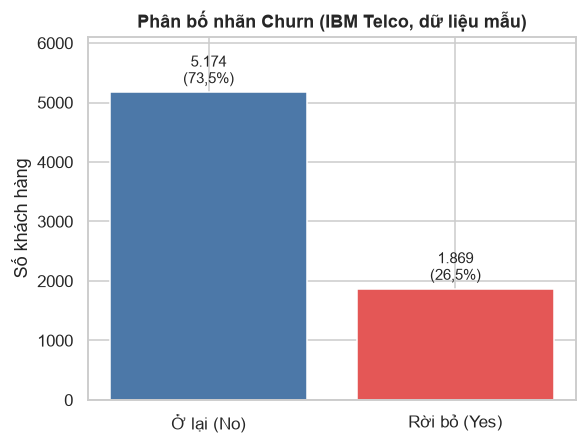

In [9]:
figure, axis = plt.subplots(figsize=(5.5, 4.2))
bar_colors = [COLOR_STAY, COLOR_CHURN]
bars = axis.bar(churn_distribution_table["Nhãn"], churn_distribution_table["Số khách"], color=bar_colors)
for bar, count, percent in zip(bars, churn_distribution_table["Số khách"], churn_distribution_table["Tỷ lệ (%)"]):
    axis.annotate(
        format_count(count) + "\n(" + format_percent(percent) + ")",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points",
    )
axis.set_title("Phân bố nhãn Churn (IBM Telco, dữ liệu mẫu)")
axis.set_ylabel("Số khách hàng")
axis.set_ylim(0, churn_distribution_table["Số khách"].max() * 1.18)
save_figure(figure, "eda_01_phan_bo_churn.png")
plt.show()

## 3. Tỷ lệ churn theo loại hợp đồng, dịch vụ Internet và phương thức thanh toán

`Tỷ lệ churn = số khách có nhãn Yes / số khách trong nhóm`. Đường nét đứt là tỷ lệ chung của toàn bộ dữ liệu. Nhóm quá ít khách thì tỷ lệ kém ổn định, nên mỗi cột đều ghi kèm số khách (n).

In [10]:
def churn_table(column_name, label, order=None):
    """Bảng tỷ lệ churn theo một cột phân loại."""
    grouped = data.groupby(column_name, observed=True)["churn_flag"].agg(["count", "sum"])
    if order is not None:
        grouped = grouped.reindex(order)
    table = grouped.reset_index()
    table.columns = [label, "Số khách", "Số khách nhãn Yes"]
    table["Tỷ lệ churn (%)"] = (table["Số khách nhãn Yes"] / table["Số khách"] * 100).round(2)
    return table


def plot_churn_rate(table, label, title, file_name, figure_size=(6.5, 4.4), wrap_width=14):
    """Biểu đồ cột tỷ lệ churn theo nhóm, có ghi số khách và đường trung bình chung."""
    figure, axis = plt.subplots(figsize=figure_size)
    sns.barplot(data=table, x=label, y="Tỷ lệ churn (%)", color=COLOR_CHURN, ax=axis)
    axis.axhline(churn_rate_overall, color="gray", linestyle="--", linewidth=1.2,
                 label="Trung bình chung: " + format_percent(churn_rate_overall))
    for index, row in table.iterrows():
        axis.annotate(
            format_percent(row["Tỷ lệ churn (%)"]) + "\n(n=" + format_count(row["Số khách"]) + ")",
            (index, row["Tỷ lệ churn (%)"]),
            ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points",
        )
    axis.set_xticks(range(len(table)))
    axis.set_xticklabels([textwrap.fill(str(v), wrap_width) for v in table[label]])
    axis.set_title(title)
    axis.set_xlabel(label)
    axis.set_ylabel("Tỷ lệ nhãn churn (%)")
    axis.set_ylim(0, table["Tỷ lệ churn (%)"].max() * 1.25)
    axis.legend(loc="upper right")
    save_figure(figure, file_name)
    plt.show()

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_04_churn_theo_hop_dong.csv
Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_02_churn_theo_hop_dong.png


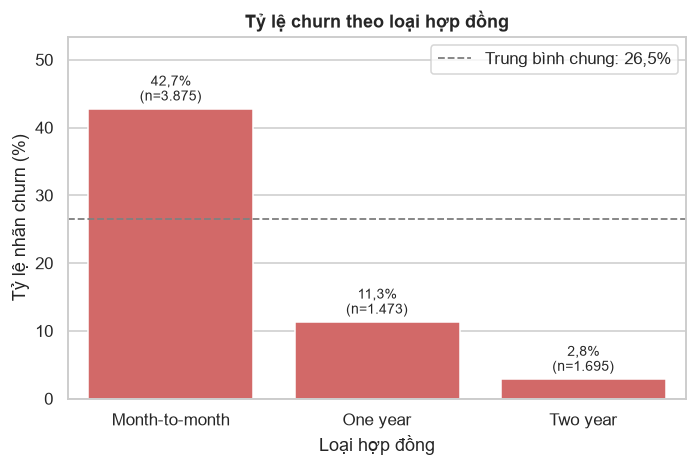

,Loại hợp đồng,Số khách,Số khách nhãn Yes,Tỷ lệ churn (%)
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [11]:
contract_table = churn_table("Contract", "Loại hợp đồng", ["Month-to-month", "One year", "Two year"])
save_table(contract_table, "eda_04_churn_theo_hop_dong.csv")
plot_churn_rate(contract_table, "Loại hợp đồng", "Tỷ lệ churn theo loại hợp đồng", "eda_02_churn_theo_hop_dong.png")
contract_table

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_05_churn_theo_internet.csv
Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_03_churn_theo_internet.png


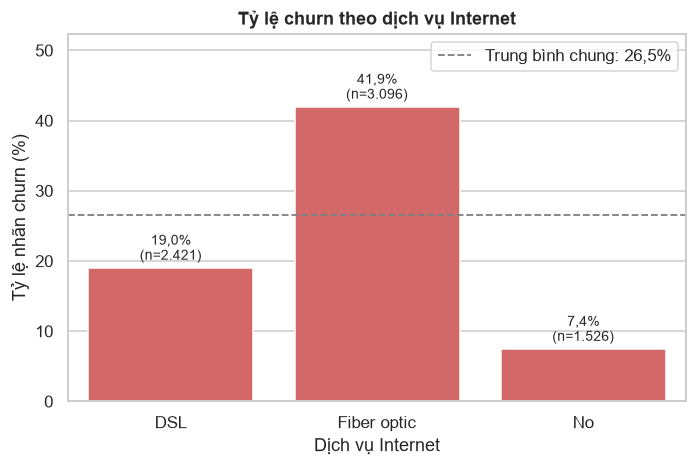

,Dịch vụ Internet,Số khách,Số khách nhãn Yes,Tỷ lệ churn (%)
0,DSL,2421,459,18.96
1,Fiber optic,3096,1297,41.89
2,No,1526,113,7.40


In [12]:
internet_table = churn_table("InternetService", "Dịch vụ Internet", ["DSL", "Fiber optic", "No"])
save_table(internet_table, "eda_05_churn_theo_internet.csv")
plot_churn_rate(internet_table, "Dịch vụ Internet", "Tỷ lệ churn theo dịch vụ Internet", "eda_03_churn_theo_internet.png")
internet_table

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_06_churn_theo_thanh_toan.csv
Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_04_churn_theo_thanh_toan.png


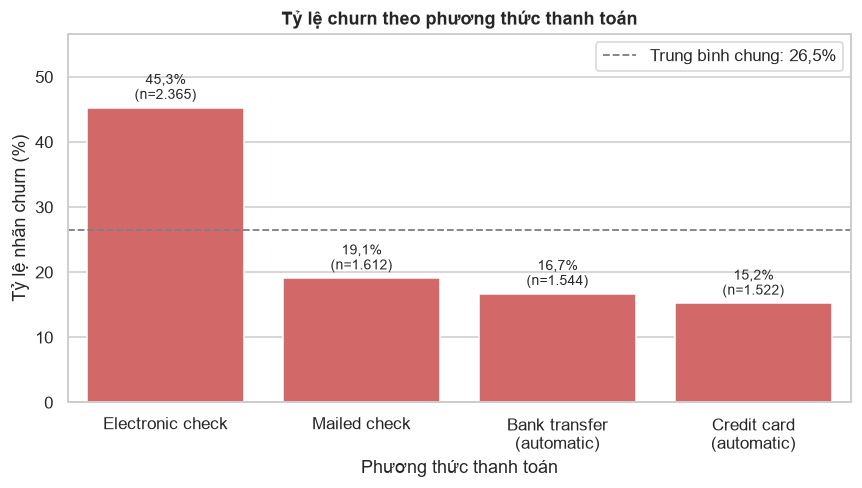

,Phương thức thanh toán,Số khách,Số khách nhãn Yes,Tỷ lệ churn (%)
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


In [13]:
payment_order = ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"]
payment_table = churn_table("PaymentMethod", "Phương thức thanh toán", payment_order)
save_table(payment_table, "eda_06_churn_theo_thanh_toan.csv")
plot_churn_rate(payment_table, "Phương thức thanh toán", "Tỷ lệ churn theo phương thức thanh toán",
                "eda_04_churn_theo_thanh_toan.png", figure_size=(8, 4.6), wrap_width=16)
payment_table

Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_05_churn_hop_dong_x_internet.png


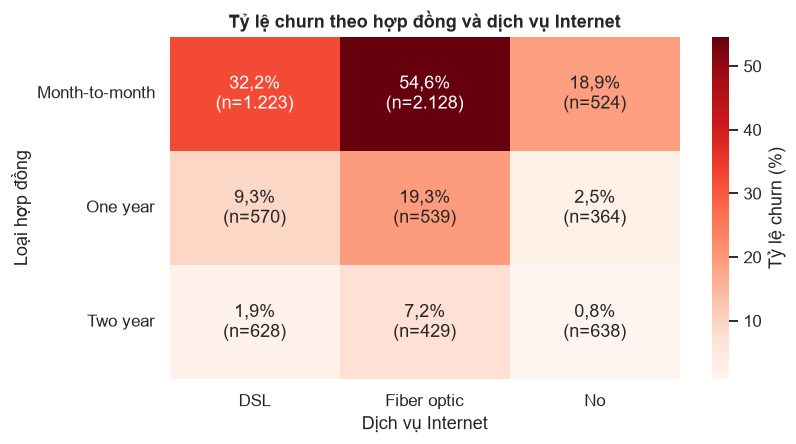

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_07_churn_hop_dong_x_internet.csv


InternetService,Loại hợp đồng,DSL,Fiber optic,No
0,Month-to-month,32.22,54.61,18.89
1,One year,9.30,19.29,2.47
2,Two year,1.91,7.23,0.78


In [14]:
# Kết hợp loại hợp đồng và dịch vụ Internet: xem nhóm nào có tỷ lệ cao nhất (kèm số khách)
pivot_rate = data.pivot_table(index="Contract", columns="InternetService", values="churn_flag", aggfunc="mean") * 100
pivot_count = data.pivot_table(index="Contract", columns="InternetService", values="churn_flag", aggfunc="count")
pivot_rate = pivot_rate.reindex(["Month-to-month", "One year", "Two year"])[["DSL", "Fiber optic", "No"]]
pivot_count = pivot_count.reindex(["Month-to-month", "One year", "Two year"])[["DSL", "Fiber optic", "No"]]

annotations = pivot_rate.copy().astype(object)
for row_name in pivot_rate.index:
    for column_name in pivot_rate.columns:
        annotations.loc[row_name, column_name] = (
            format_percent(pivot_rate.loc[row_name, column_name])
            + "\n(n=" + format_count(pivot_count.loc[row_name, column_name]) + ")"
        )

figure, axis = plt.subplots(figsize=(7.6, 4.2))
sns.heatmap(pivot_rate, annot=annotations.values, fmt="", cmap="Reds", cbar_kws={"label": "Tỷ lệ churn (%)"}, ax=axis)
axis.tick_params(axis="y", rotation=0)  # nhãn hàng nằm ngang, không đè lên tiêu đề trục
axis.set_title("Tỷ lệ churn theo hợp đồng và dịch vụ Internet")
axis.set_xlabel("Dịch vụ Internet")
axis.set_ylabel("Loại hợp đồng")
save_figure(figure, "eda_05_churn_hop_dong_x_internet.png")
plt.show()

heatmap_table = pivot_rate.round(2).reset_index().rename(columns={"Contract": "Loại hợp đồng"})
save_table(heatmap_table, "eda_07_churn_hop_dong_x_internet.csv")
heatmap_table

## 4. Quan hệ giữa `tenure`, mức phí hằng tháng (dữ liệu mẫu), `TotalCharges` và churn

In [15]:
numeric_columns = {"tenure": "Thời gian sử dụng (tháng)",
                   "MonthlyCharges": "Mức phí hằng tháng (dữ liệu mẫu)",
                   "TotalCharges": "Tổng mức phí (dữ liệu mẫu)"}

summary_rows = []
for column_name, label in numeric_columns.items():
    for group_label in [LABEL_STAY, LABEL_CHURN]:
        values = data.loc[data["Nhãn"] == group_label, column_name].dropna()
        summary_rows.append((
            label, group_label, len(values),
            round(values.mean(), 2), round(values.median(), 2), round(values.std(), 2),
            round(values.min(), 2), round(values.max(), 2),
        ))
numeric_summary = pd.DataFrame(
    summary_rows, columns=["Biến", "Nhóm", "Số khách (không thiếu)", "Trung bình", "Trung vị", "Độ lệch chuẩn", "Nhỏ nhất", "Lớn nhất"]
)
save_table(numeric_summary, "eda_08_thong_ke_bien_so.csv")
numeric_summary

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_08_thong_ke_bien_so.csv


,Biến,Nhóm,Số khách (không thiếu),Trung bình,Trung vị,Độ lệch chuẩn,Nhỏ nhất,Lớn nhất
0,Thời gian sử dụng (tháng),Ở lại (No),5174,37.57,38.00,24.11,0.00,72.00
1,Thời gian sử dụng (tháng),Rời bỏ (Yes),1869,17.98,10.00,19.53,1.00,72.00
2,Mức phí hằng tháng (dữ liệu mẫu),Ở lại (No),5174,61.27,64.43,31.09,18.25,118.75
3,Mức phí hằng tháng (dữ liệu mẫu),Rời bỏ (Yes),1869,74.44,79.65,24.67,18.85,118.35
4,Tổng mức phí (dữ liệu mẫu),Ở lại (No),5163,2555.34,1683.60,2329.46,18.80,8672.45
5,Tổng mức phí (dữ liệu mẫu),Rời bỏ (Yes),1869,1531.80,703.55,1890.82,18.85,8684.80


Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_06_phan_bo_bien_so.png


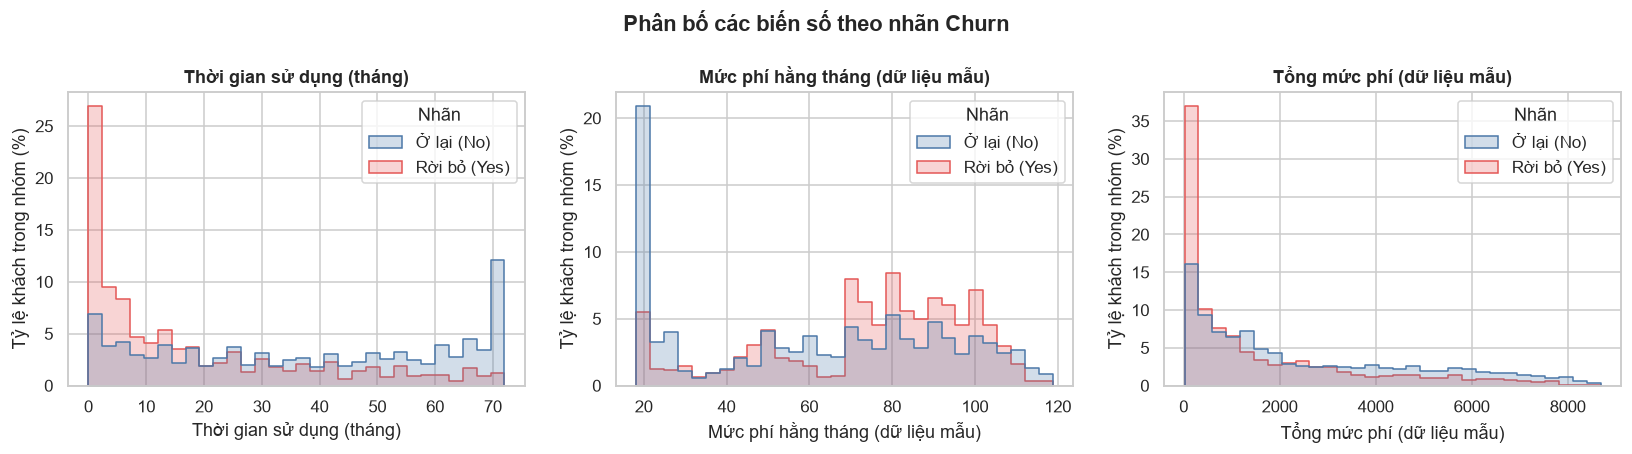

In [16]:
# Phân bố từng biến số theo nhãn (chuẩn hóa theo từng nhóm để so sánh hình dạng, không bị lệch vì số khách khác nhau)
figure, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for axis, (column_name, label) in zip(axes, numeric_columns.items()):
    sns.histplot(
        data=data.dropna(subset=[column_name]), x=column_name, hue="Nhãn", hue_order=[LABEL_STAY, LABEL_CHURN],
        palette=PALETTE, stat="percent", common_norm=False, element="step", bins=30, ax=axis,
    )
    axis.set_title(label)
    axis.set_xlabel(label)
    axis.set_ylabel("Tỷ lệ khách trong nhóm (%)")
figure.suptitle("Phân bố các biến số theo nhãn Churn", fontweight="bold")
save_figure(figure, "eda_06_phan_bo_bien_so.png")
plt.show()

Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_07_boxplot_bien_so.png


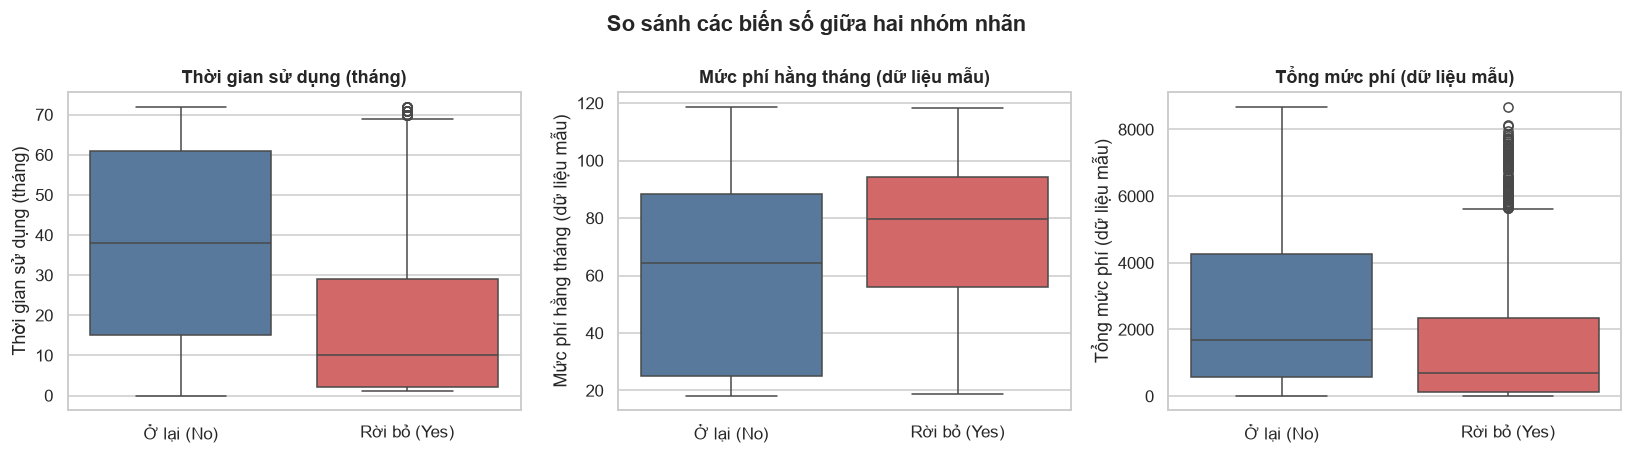

In [17]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for axis, (column_name, label) in zip(axes, numeric_columns.items()):
    sns.boxplot(
        data=data, x="Nhãn", y=column_name, order=[LABEL_STAY, LABEL_CHURN],
        palette=PALETTE, hue="Nhãn", legend=False, ax=axis,
    )
    axis.set_title(label)
    axis.set_xlabel("")
    axis.set_ylabel(label)
figure.suptitle("So sánh các biến số giữa hai nhóm nhãn", fontweight="bold")
save_figure(figure, "eda_07_boxplot_bien_so.png")
plt.show()

### 4.1. Nhóm `tenure` (D-05) và retention proxy

Nhóm tenure: 0–6, 7–12, 13–24, 25–36, 37–48, 49–60, >60 tháng. `retention proxy = 1 − tỷ lệ churn của nhóm`.

**Lưu ý:** dữ liệu Telco chỉ là **ảnh chụp tại một thời điểm**, không có ngày đăng ký. Retention proxy ở đây là ước lượng theo nhóm thâm niên, **không phải** đường giữ chân khách theo thời gian.

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_09_churn_theo_nhom_tenure.csv
Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_08_churn_theo_nhom_tenure.png


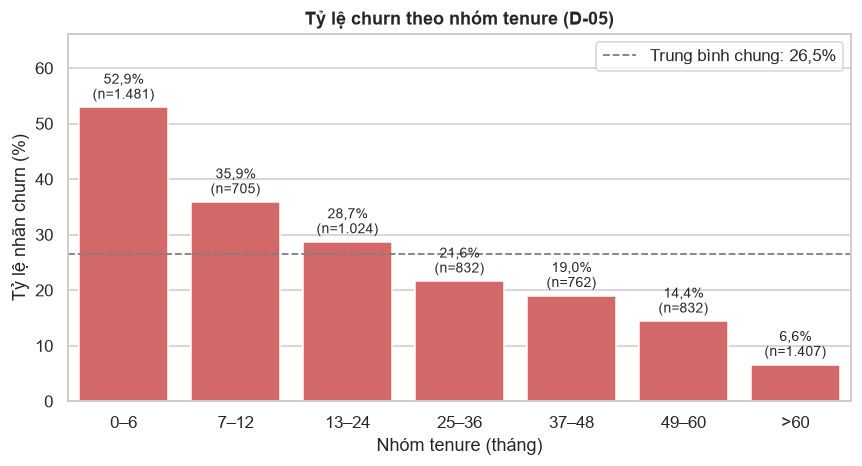

,Nhóm tenure (tháng),Số khách,Số khách nhãn Yes,Tỷ lệ churn (%),Retention proxy (%)
0,0–6,1481,784,52.94,47.06
1,7–12,705,253,35.89,64.11
2,13–24,1024,294,28.71,71.29
3,25–36,832,180,21.63,78.37
4,37–48,762,145,19.03,80.97
5,49–60,832,120,14.42,85.58
6,>60,1407,93,6.61,93.39


In [18]:
tenure_bins = [-1, 6, 12, 24, 36, 48, 60, 1000]
tenure_labels = ["0–6", "7–12", "13–24", "25–36", "37–48", "49–60", ">60"]
data["Nhóm tenure"] = pd.cut(data["tenure"], bins=tenure_bins, labels=tenure_labels)

tenure_table = churn_table("Nhóm tenure", "Nhóm tenure (tháng)", tenure_labels)
tenure_table["Retention proxy (%)"] = (100 - tenure_table["Tỷ lệ churn (%)"]).round(2)
save_table(tenure_table, "eda_09_churn_theo_nhom_tenure.csv")
plot_churn_rate(tenure_table, "Nhóm tenure (tháng)", "Tỷ lệ churn theo nhóm tenure (D-05)",
                "eda_08_churn_theo_nhom_tenure.png", figure_size=(8, 4.4), wrap_width=10)
tenure_table

Ranh giới tam phân vị của MonthlyCharges: [18.25, 50.4, 83.9, 118.75]
Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_10_churn_theo_bac_muc_phi.csv
Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_09_churn_theo_bac_muc_phi.png


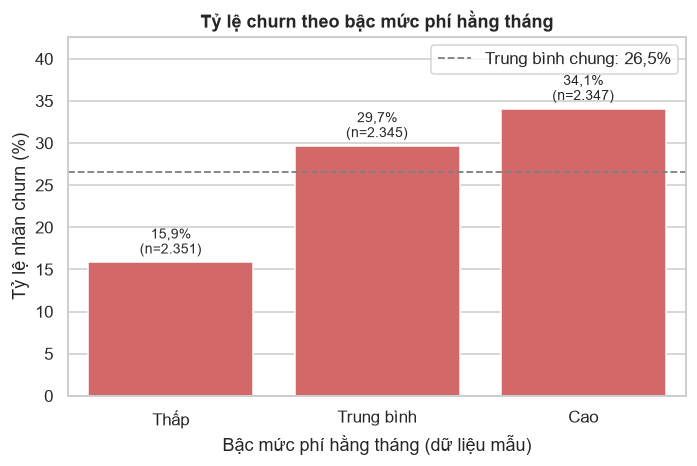

,Bậc mức phí hằng tháng (dữ liệu mẫu),Số khách,Số khách nhãn Yes,Tỷ lệ churn (%)
0,Thấp,2351,373,15.87
1,Trung bình,2345,696,29.68
2,Cao,2347,800,34.09


In [19]:
# Tỷ lệ churn theo bậc mức phí hằng tháng (chia theo tam phân vị, dùng lại cho phân khúc ở dashboard)
data["Bậc mức phí"] = pd.qcut(data["MonthlyCharges"], q=3, labels=["Thấp", "Trung bình", "Cao"])
charge_edges = data["MonthlyCharges"].quantile([0, 1 / 3, 2 / 3, 1]).round(2).tolist()
print("Ranh giới tam phân vị của MonthlyCharges:", charge_edges)

charge_table = churn_table("Bậc mức phí", "Bậc mức phí hằng tháng (dữ liệu mẫu)", ["Thấp", "Trung bình", "Cao"])
save_table(charge_table, "eda_10_churn_theo_bac_muc_phi.csv")
plot_churn_rate(charge_table, "Bậc mức phí hằng tháng (dữ liệu mẫu)", "Tỷ lệ churn theo bậc mức phí hằng tháng",
                "eda_09_churn_theo_bac_muc_phi.png", figure_size=(6.5, 4.4), wrap_width=18)
charge_table

### 4.2. Quan hệ giữa các biến số

`TotalCharges` gần bằng `tenure × MonthlyCharges` nên ba biến này **tương quan mạnh với nhau** (đa cộng tuyến). Điều này ảnh hưởng đến cách đọc hệ số của Logistic Regression ở bước mô hình hóa, nhưng không ảnh hưởng đến khả năng dự báo của các mô hình cây.

Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_10_tuong_quan_bien_so.png


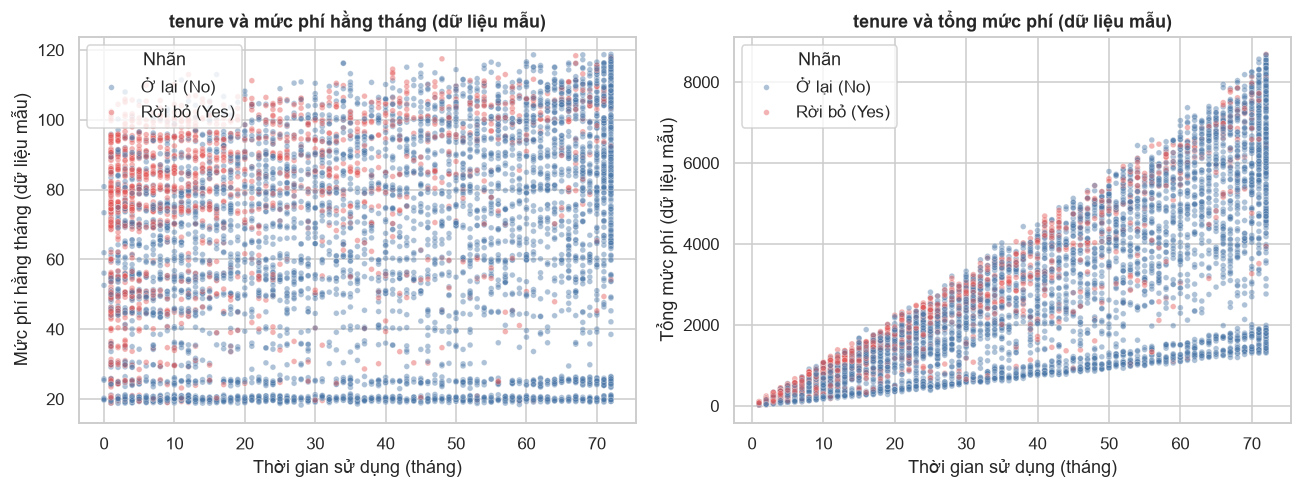

In [20]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.6))

sns.scatterplot(data=data, x="tenure", y="MonthlyCharges", hue="Nhãn", hue_order=[LABEL_STAY, LABEL_CHURN],
                palette=PALETTE, alpha=0.45, s=14, ax=axes[0])
axes[0].set_title("tenure và mức phí hằng tháng (dữ liệu mẫu)")
axes[0].set_xlabel("Thời gian sử dụng (tháng)")
axes[0].set_ylabel("Mức phí hằng tháng (dữ liệu mẫu)")

sns.scatterplot(data=data.dropna(subset=["TotalCharges"]), x="tenure", y="TotalCharges", hue="Nhãn",
                hue_order=[LABEL_STAY, LABEL_CHURN], palette=PALETTE, alpha=0.45, s=14, ax=axes[1])
axes[1].set_title("tenure và tổng mức phí (dữ liệu mẫu)")
axes[1].set_xlabel("Thời gian sử dụng (tháng)")
axes[1].set_ylabel("Tổng mức phí (dữ liệu mẫu)")

save_figure(figure, "eda_10_tuong_quan_bien_so.png")
plt.show()

Số khách có TotalCharges lệch hơn 25% so với tenure x MonthlyCharges: 27 trên 7032 khách so sánh được
Đã lưu hình : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\figures\eda_11_ma_tran_tuong_quan.png


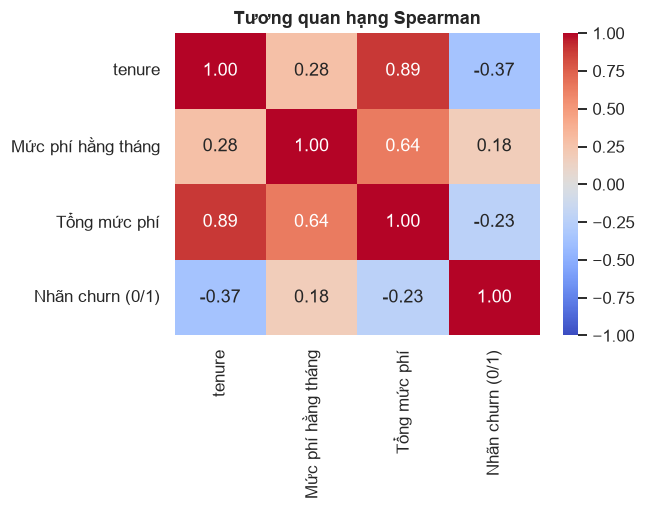

Đã lưu bảng : E:\Luu_Bai\Thực Tập Chuyên Ngành HK_4\Bài Tập\crm-churn-explainable\ml\results\metrics\eda_11_ma_tran_tuong_quan.csv


,Biến,tenure,Mức phí hằng tháng,Tổng mức phí,Nhãn churn (0/1)
0,tenure,1.000,0.276,0.889,-0.367
1,Mức phí hằng tháng,0.276,1.000,0.638,0.185
2,Tổng mức phí,0.889,0.638,1.000,-0.232
3,Nhãn churn (0/1),-0.367,0.185,-0.232,1.000


In [21]:
# Kiểm: TotalCharges so với tenure x MonthlyCharges (chỉ cảnh báo, giá cước có thể đã đổi theo thời gian)
comparable = data["TotalCharges"].notna() & (data["tenure"] > 0)
expected_total = data["tenure"] * data["MonthlyCharges"]
relative_gap = (data["TotalCharges"] - expected_total).abs() / expected_total
big_gap_count = int((relative_gap[comparable] > 0.25).sum())
print("Số khách có TotalCharges lệch hơn 25% so với tenure x MonthlyCharges:", big_gap_count,
      "trên", int(comparable.sum()), "khách so sánh được")

# Hệ số tương quan hạng Spearman (không giả định quan hệ tuyến tính). churn_flag là biến 0/1.
correlation_columns = ["tenure", "MonthlyCharges", "TotalCharges", "churn_flag"]
correlation_labels = ["tenure", "Mức phí hằng tháng", "Tổng mức phí", "Nhãn churn (0/1)"]
correlation = data[correlation_columns].corr(method="spearman")
correlation.index = correlation_labels
correlation.columns = correlation_labels

figure, axis = plt.subplots(figsize=(6, 4.8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axis)
axis.set_title("Tương quan hạng Spearman")
save_figure(figure, "eda_11_ma_tran_tuong_quan.png")
plt.show()

correlation_table = correlation.round(3).reset_index().rename(columns={"index": "Biến"})
save_table(correlation_table, "eda_11_ma_tran_tuong_quan.csv")
correlation_table

## 5. Các điểm đáng chú ý (tính tự động từ dữ liệu)

Các câu dưới đây được **tính ra từ dữ liệu**, không gõ tay, để số liệu trong báo cáo luôn khớp với bảng.

In [22]:
def best_and_worst(table, label):
    ordered = table.sort_values("Tỷ lệ churn (%)")
    low, high = ordered.iloc[0], ordered.iloc[-1]
    return (
        "- Theo " + label.lower() + ": cao nhất ở '" + str(high.iloc[0]) + "' (" + format_percent(high["Tỷ lệ churn (%)"])
        + ", n=" + format_count(high["Số khách"]) + "), thấp nhất ở '" + str(low.iloc[0]) + "' ("
        + format_percent(low["Tỷ lệ churn (%)"]) + ", n=" + format_count(low["Số khách"]) + ")."
    )


print("- Tỷ lệ nhãn churn toàn bộ:", format_percent(churn_rate_overall), "(" + format_count(churn_counts["Yes"]) + "/" + format_count(len(data)) + " khách).")
print(best_and_worst(contract_table, "Loại hợp đồng"))
print(best_and_worst(internet_table, "Dịch vụ Internet"))
print(best_and_worst(payment_table, "Phương thức thanh toán"))
print(best_and_worst(tenure_table, "Nhóm tenure"))
print(best_and_worst(charge_table, "Bậc mức phí"))

median_tenure_stay = data.loc[data["Churn"] == "No", "tenure"].median()
median_tenure_churn = data.loc[data["Churn"] == "Yes", "tenure"].median()
print("- Trung vị tenure: nhóm Ở lại =", median_tenure_stay, "tháng, nhóm Rời bỏ =", median_tenure_churn, "tháng.")
print("- Tương quan hạng (Spearman) giữa tenure và nhãn churn:", round(correlation.loc["tenure", "Nhãn churn (0/1)"], 3),
      "| giữa mức phí hằng tháng và nhãn churn:", round(correlation.loc["Mức phí hằng tháng", "Nhãn churn (0/1)"], 3))
print("- tenure = 0:", int((data["tenure"] == 0).sum()), "khách, đều có TotalCharges trống và nhãn No.")

- Tỷ lệ nhãn churn toàn bộ: 26,5% (1.869/7.043 khách).
- Theo loại hợp đồng: cao nhất ở 'Month-to-month' (42,7%, n=3.875), thấp nhất ở 'Two year' (2,8%, n=1.695).
- Theo dịch vụ internet: cao nhất ở 'Fiber optic' (41,9%, n=3.096), thấp nhất ở 'No' (7,4%, n=1.526).
- Theo phương thức thanh toán: cao nhất ở 'Electronic check' (45,3%, n=2.365), thấp nhất ở 'Credit card (automatic)' (15,2%, n=1.522).
- Theo nhóm tenure: cao nhất ở '0–6' (52,9%, n=1.481), thấp nhất ở '>60' (6,6%, n=1.407).
- Theo bậc mức phí: cao nhất ở 'Cao' (34,1%, n=2.347), thấp nhất ở 'Thấp' (15,9%, n=2.351).
- Trung vị tenure: nhóm Ở lại = 38.0 tháng, nhóm Rời bỏ = 10.0 tháng.
- Tương quan hạng (Spearman) giữa tenure và nhãn churn: -0.367 | giữa mức phí hằng tháng và nhãn churn: 0.185
- tenure = 0: 11 khách, đều có TotalCharges trống và nhãn No.


## 6. Giới hạn khi đọc kết quả EDA (đưa vào báo cáo mục 4.9 và Chương 5)

1. **Tương quan, không phải nhân quả (R-02).** Việc nhóm "Month-to-month" có tỷ lệ churn cao hơn chỉ cho thấy hai thứ đi cùng nhau trong dữ liệu mẫu, không chứng minh loại hợp đồng *gây ra* churn.
2. **Dữ liệu mẫu (R-12).** IBM Telco là bộ dữ liệu minh họa, không thể suy rộng thẳng sang một nhà mạng thực tế hay sang Việt Nam.
3. **Ảnh chụp một thời điểm.** Không có ngày đăng ký/ngày rời bỏ, nên không dựng được cohort thật; nhóm tenure chỉ là ước lượng (D-05).
4. **Chưa có khoảng tin cậy.** Các chênh lệch tỷ lệ giữa nhóm nhỏ (n nhỏ) có thể do ngẫu nhiên; mỗi hình đã ghi n để người đọc tự cân nhắc.
5. **Đây là bước mô tả.** Việc chọn đặc trưng và mô hình sẽ dựa trên Pipeline và cross-validation ở `03_model_experiments.ipynb`, không dựa trên kết luận từ EDA.

In [23]:
# Liệt kê các tệp notebook này đã xuất ra (để kiểm tra và đưa vào gói nộp)
print("HÌNH (ml/results/figures):")
for path in sorted(FIGURE_FOLDER.glob("eda_*.png")):
    print("  -", path.name)
print("BẢNG (ml/results/metrics):")
for path in sorted(METRICS_FOLDER.glob("eda_*.csv")):
    print("  -", path.name)

HÌNH (ml/results/figures):
  - eda_01_phan_bo_churn.png
  - eda_02_churn_theo_hop_dong.png
  - eda_03_churn_theo_internet.png
  - eda_04_churn_theo_thanh_toan.png
  - eda_05_churn_hop_dong_x_internet.png
  - eda_06_phan_bo_bien_so.png
  - eda_07_boxplot_bien_so.png
  - eda_08_churn_theo_nhom_tenure.png
  - eda_09_churn_theo_bac_muc_phi.png
  - eda_10_tuong_quan_bien_so.png
  - eda_11_ma_tran_tuong_quan.png
BẢNG (ml/results/metrics):
  - eda_01_chat_luong_du_lieu.csv
  - eda_02_thong_ke_cot.csv
  - eda_03_phan_bo_churn.csv
  - eda_04_churn_theo_hop_dong.csv
  - eda_05_churn_theo_internet.csv
  - eda_06_churn_theo_thanh_toan.csv
  - eda_07_churn_hop_dong_x_internet.csv
  - eda_08_thong_ke_bien_so.csv
  - eda_09_churn_theo_nhom_tenure.csv
  - eda_10_churn_theo_bac_muc_phi.csv
  - eda_11_ma_tran_tuong_quan.csv
